# Talent abilities: overview

This notebook compares every new talent ability (Parasite → Soul Reflection in
`client/src/ui/visuals/spell_icons.rs`) on one axis: the caster's **modified skill**
(`skill[n][5]`). Each ability has a dedicated notebook in this folder with the full formula,
validation against the Rust unit tests, and detailed plots. This page answers three
cross-cutting questions:

1. **Where does each ability stop scaling?** The skill value at which its primary effect hits a
   clamp.
2. **How does scaling compare within a class?** Each primary effect is normalised to its value
   at skill 300, the endgame target (top-rank players reach modified skill 275–300).
3. **Soul Reflection.** It has no scaling output, only a `power ≥ resist` threshold, so it is
   charted here instead of getting its own notebook.

| Class | Ability | Notebook | Primary effect plotted here |
|---|---|---|---|
| Mercenary | Parasite | `mercenary_parasite.ipynb` | DoT HP/s per target |
| | Contagion | `mercenary_contagion.ipynb` | DoT HP/s per target |
| | Gunpowder Flash | `mercenary_gunpowder_flash.ipynb` | enemy action-speed points removed |
| | Disarm | `mercenary_disarm.ipynb` | enemy weapon-skill penalty |
| | Deliver Death | `mercenary_deliver_death.ipynb` | damage scale % |
| | Blade Dance | `mercenary_blade_dance.ipynb` | damage scale % (active only) |
| Templar | Rains of Renewal | `templar_rains_of_renewal.ipynb` | HP/s healed |
| | Gash | `templar_gash.ipynb` | fixed damage multiple of WV |
| | Sun's Blessing | `templar_suns_blessing.ipynb` | bonus to attributes / armor / WV |
| | Seeing Red | `templar_seeing_red.ipynb` | buff duration |
| | Thunderous Fury | `templar_thunderous_fury.ipynb` | mean raw damage per target |
| | Inner Strength | `templar_inner_strength.ipynb` | weapon-skill bonus |
| Harakim | Lava Blast | `harakim_lava_blast.ipynb` | direct + full burn damage |
| | Ice Stun | `harakim_ice_stun.ipynb` | stun duration |
| | Anguish – Lava | `harakim_anguish_lava.ipynb` | next-Blast multiplier |
| | Anguish – Ice | `harakim_anguish_ice.ipynb` | armor & WV penalty |
| | Revenant Conduit | `harakim_revenant_conduit.ipynb` | companion skill boost % |
| | Spectral Pact | `harakim_spectral_pact.ipynb` | damage redirect % |
| Aura | Aura of Despair | `aura_of_despair.ipynb` | attribute penalty |
| | War Banner | `aura_war_banner.ipynb` | armor & WV bonus |

Skipped, per `PLAN.md` §3: Kindred Spirit / Spellcaster Kindred Spirit, Anguish – Earth, Element
Switching (a flat +20%, covered in the Lava Blast and Ice Stun notebooks), and the Seyan'Du
runes.

All curves below assume a target with **0 immunity**, a **Mercenary** caster for Mercenary
spells, and a **Harakim** caster for Harakim spells. Abilities that read the raw skill (Gash,
Rains, Sun's Blessing, Seeing Red, Thunderous Fury, Inner Strength, Anguish, companion spells and
auras) ignore race.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
P_WIDE = np.arange(1, 1001)   # used only to locate saturation points beyond the plotted range

# Primary effects

Each entry is the compact form of the formula derived and validated in that ability's notebook.

In [2]:
def merc(p):
    return mm.spell_power(p, 0, "Mercenary")


def hara(p):
    return mm.spell_power(p, 0, "Harakim")


def aura_power(p):
    return 50 + mm.idiv(p, 2)


ABILITIES = {
    "Mercenary": {
        "Parasite (HP/s)": lambda p: mm.dot_tick(merc(p), "parasite"),
        "Contagion (HP/s)": lambda p: mm.dot_tick(merc(p), "contagion"),
        "Gunpowder Flash (slow pts)": lambda p: mm.clamp(3 + mm.idiv(merc(p), 40), 6, 20),
        "Disarm (−weapon skill)": lambda p: np.maximum(mm.knee_300(merc(p), 0, 150), 3),
        "Deliver Death / Blade Dance (scale %)": lambda p: mm.knee_300(p, 50, 150),
    },
    "Templar": {
        "Rains of Renewal (HP/s)": lambda p: mm.dot_tick(p),
        "Gash (×WV fixed part)": lambda p: (100 + np.maximum(mm.knee_300(p, 0, 600), 30)) / 100,
        "Sun's Blessing (+all)": lambda p: np.minimum(mm.knee_300(p, 6, 90), 120),
        "Seeing Red (duration s)": lambda p: 15 + mm.clamp(mm.idiv(p, 5), 0, 75),
        "Thunderous Fury (mean raw dmg)": lambda p: (lambda b: b + mm.rand_mod_mean(b))(np.maximum(1, mm.idiv(np.asarray(p) * 3, 4))),
        "Inner Strength (+weapon skill)": lambda p: mm.knee_300(p, 6, 150),
    },
    "Harakim": {
        "Lava Blast (direct + burn)": lambda p: 2 * hara(p) + 6 * mm.dot_tick(np.maximum(1, hara(p)), "lava"),
        "Ice Stun (stun s)": lambda p: (hara(p) + mm.TICKS) / mm.TICKS,
        "Anguish – Lava (Blast ×%)": lambda p: mm.knee_300(p, 150, 200),
        "Anguish – Ice (−armor/WV)": lambda p: mm.clamp(mm.knee_300(p, 0, 30), 2, 45),
        "Revenant Conduit (boost %)": lambda p: mm.knee_300(p, 30, 150),
        "Spectral Pact (redirect %)": lambda p: np.minimum(mm.knee_300(p, 30, 75), 90),
    },
    "Aura": {
        "Aura of Despair (−attributes)": lambda p: mm.idiv(aura_power(p), 3),
        "War Banner (+armor/WV)": lambda p: np.maximum(1, mm.idiv(aura_power(p), 10)),
    },
}

# Validation

These spot checks pin the compact forms to the values asserted in the Rust unit tests and in the
per-ability notebooks.

In [3]:
A = {name: f for group in ABILITIES.values() for name, f in group.items()}
assert mm.clamp(3 + mm.idiv(0, 40), 6, 20) == 6 and mm.clamp(3 + mm.idiv(400, 40), 6, 20) == 13
scale = A["Deliver Death / Blade Dance (scale %)"]
assert scale(0) == 50 and scale(150) == 100 and scale(300) == 150 and scale(450) == 175
assert mm.knee_300(40, 0, 150) == 20 and mm.knee_300(500, 0, 150) == 200   # Disarm p' 40 / 500
lava = A["Anguish – Lava (Blast ×%)"]
assert 100 * lava(25) // 100 == 154 and lava(300) == 200 and lava(450) == 212
ice = A["Anguish – Ice (−armor/WV)"]
assert ice(0) == 2 and ice(105) == 10 and ice(300) == 30 and ice(350) == 32 and ice(600) == 45
pact = A["Spectral Pact (redirect %)"]
assert pact(50) == 37 and pact(300) == 75 and pact(350) == 78 and pact(500) == 90 and pact(1000) == 90
rev = A["Revenant Conduit (boost %)"]
assert rev(105) == 72 and rev(300) == 150 and rev(450) == 180
assert A["Gash (×WV fixed part)"](0) == 1.3 and A["Gash (×WV fixed part)"](450) == 8.5
assert A["Sun's Blessing (+all)"](40) == 17 and A["Sun's Blessing (+all)"](450) == 111 and A["Sun's Blessing (+all)"](2000) == 120
assert A["Inner Strength (+weapon skill)"](50) == 30 and A["Inner Strength (+weapon skill)"](450) == 186
print("overview formulas OK")

overview formulas OK


# Where does each ability stop scaling?

"Saturates at" is the lowest modified skill at which the primary effect reaches its ceiling. It
is searched up to skill 1000. A dash means the effect never stops growing.

In [4]:
rows = []
for cls, group in ABILITIES.items():
    for name, f in group.items():
        v = np.asarray(f(P_WIDE), dtype=float)
        sat = "—"
        if v[-1] == v[-200:].min() and np.ptp(v[-200:]) == 0:
            sat = int(P_WIDE[np.argmax(v == v[-1])])
        at = [float(np.asarray(f(s))) for s in (105, 120, 300, 350)]
        rows.append((cls, name, *at, sat))

print(f"{'class':<10} {'ability':<40} {'@105':>8} {'@120':>8} {'@300':>8} {'@350':>8}  saturates at")
for cls, name, a, b, c, d, sat in rows:
    print(f"{cls:<10} {name:<40} {a:>8.1f} {b:>8.1f} {c:>8.1f} {d:>8.1f}  {sat}")

class      ability                                      @105     @120     @300     @350  saturates at
Mercenary  Parasite (HP/s)                              82.0     94.0    236.0    275.0  —
Mercenary  Contagion (HP/s)                            164.0    188.0    472.0    550.0  —
Mercenary  Gunpowder Flash (slow pts)                    6.0      6.0     10.0     12.0  648
Mercenary  Disarm (−weapon skill)                       55.0     63.0    153.0    166.0  —
Mercenary  Deliver Death / Blade Dance (scale %)        85.0     90.0    150.0    158.0  —
Templar    Rains of Renewal (HP/s)                      78.0     90.0    225.0    262.0  —
Templar    Gash (×WV fixed part)                         3.1      3.4      7.0      7.5  —
Templar    Sun's Blessing (+all)                        35.0     39.0     90.0     97.0  515
Templar    Seeing Red (duration s)                      36.0     39.0     75.0     85.0  375
Templar    Thunderous Fury (mean raw dmg)              116.5    134.5    

# Normalised scaling per class

Each curve is divided by its own value at modified skill 300, the endgame target. A curve that
reaches 1.0 before 300 has saturated early, so further skill is wasted on that ability. Under the
knee-300 convention a curve reaches exactly 1.0 at 300 and keeps rising at half slope beyond it.

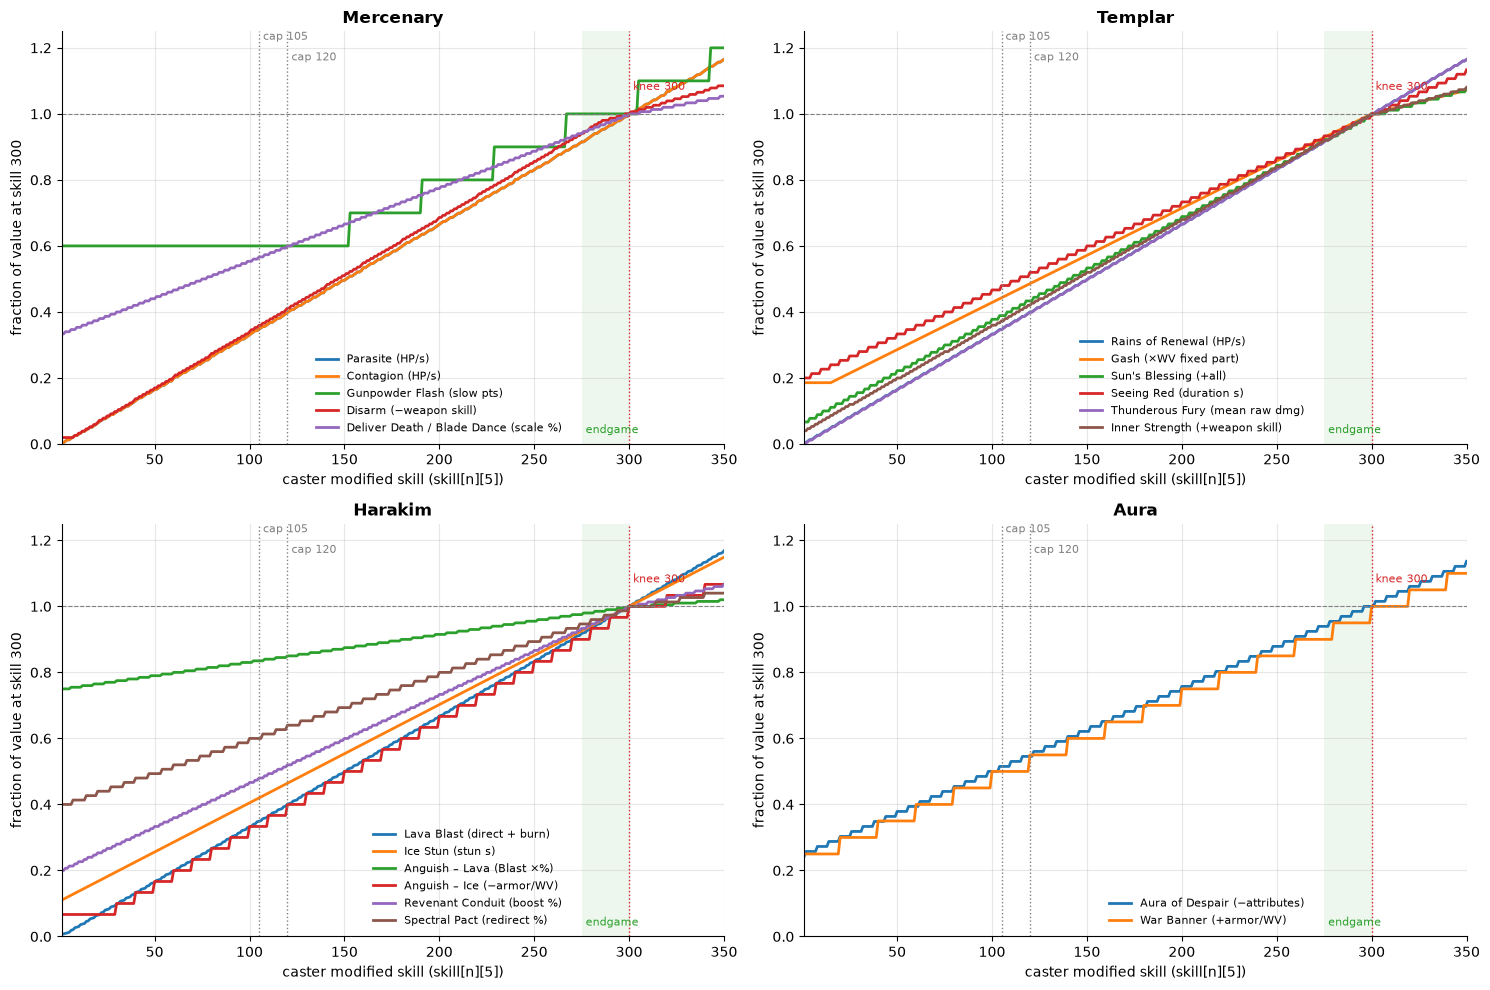

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
i300 = int(np.flatnonzero(P == mm.SKILL_KNEE)[0])
for ax, (cls, group) in zip(axes.flat, ABILITIES.items()):
    for name, f in group.items():
        v = np.asarray(f(P), dtype=float)
        ax.plot(P, v / v[i300], label=name)
    ax.axhline(1.0, color="grey", lw=0.8, ls="--")
    mm.skill_axis(ax, "fraction of value at skill 300", cls)
    mm.mark_caps(ax, extra=[(mm.SKILL_KNEE, "knee 300")])
    ax.set_ylim(0, 1.25)
    ax.legend(fontsize=8, loc="lower right", bbox_to_anchor=(0.77, 0))
plt.tight_layout()

# Soul Reflection: landing threshold

Soul Reflection (150 endurance, 30 s cooldown, radius 8, NPCs only) routs every NPC whose
effective resist does not exceed the caster's modified skill:

$$
\text{routed} \iff p \ \ge\ \left\lfloor \frac{100 \cdot \text{Resist}}{100 + \text{pen}\%} \right\rfloor
$$

Players are never affected. A routed NPC flees for a fixed 10 s, so the skill only decides
**which** NPCs flee, not how long. With spell penetration, the highest affected Resist grows to
roughly $p\,(100 + \text{pen})/100$.

Source: `server/src/driver/skill/auras.rs::skill_soul_reflection`.

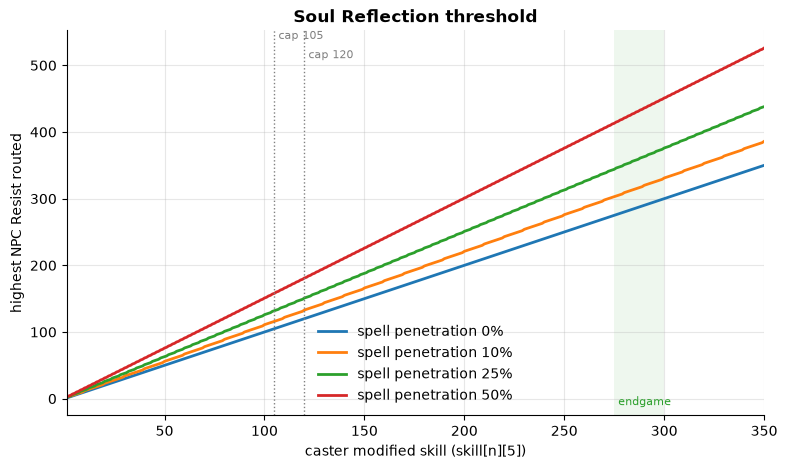

In [6]:
def max_resist_routed(p, pen=0):
    """Largest target Resist value that Soul Reflection still routs."""
    r = np.arange(0, 1001)
    eff = mm.effective_resist(r, pen)
    ok = np.asarray(eff)[None, :] <= np.asarray(p)[:, None]
    return np.where(ok.any(axis=1), r[np.argmax(~ok, axis=1) - 1], -1)


assert max_resist_routed(np.array([50]))[0] == 50          # resist == power is routed
assert max_resist_routed(np.array([100]), 25)[0] == 126    # 126*100/125 = 100

fig, ax = plt.subplots()
for pen in (0, 10, 25, 50):
    ax.plot(P, max_resist_routed(P, pen), label=f"spell penetration {pen}%")
mm.skill_axis(ax, "highest NPC Resist routed", "Soul Reflection threshold")
mm.mark_caps(ax)
ax.legend()

# Observations

## Scaling

- Ten abilities now follow the mod-300 knee: linear to modified skill 300, then half slope.
  They are Disarm, Deliver Death, Blade Dance, Gash, Sun's Blessing, Inner Strength, Anguish
  (Lava), Anguish (Ice), Revenant Conduit and Spectral Pact. Before, Disarm saturated at about 96,
  Anguish (Lava) and Revenant Conduit at 100, Spectral Pact at 150, and Deliver Death, Blade Dance
  and Gash at 200. Top-rank players (modified skill 275–300) wasted half their skill on them.
- The hard limits that remain sit past the endgame: Spectral Pact stops at 90% at skill 500,
  Sun's Blessing at +120 at 515, and Anguish (Ice) at −45 at 600.
- The cost is a weaker mid-game. At the raise cap of 105 Spectral Pact redirects 45% (before
  61%), Revenant Conduit boosts +72% (before +150%), and Gash deals about 20% less. At 120 Disarm
  removes 63 Weapon Skill (before 150) and Deliver Death and Blade Dance scale at 90%.
- Inner Strength and Disarm still pin the melee hit table early. +40 Weapon Skill pins an even
  fight, and Inner Strength reaches it at skill 71. Disarm pins an equal opponent from skill 79.
- Gunpowder Flash sits on its 6-point floor until p′ reaches 120 and slows only 10 points at skill
  300, so a skill-1 Flash and a skill-115 Flash slow by the same amount.
- Seeing Red's skill only buys duration, which covers the whole 60 s cycle from skill 225 and
  stops growing at 375. The bonus itself is 3× the current weapon value.
- Parasite, Contagion, Rains, Thunderous Fury, Lava Blast, Ice Stun and both auras grow linearly
  with no knee. Only target Immunity bounds them, and only for spells that use `spell_immunity`.
  Rains, Thunderous Fury, the Ice Stun burst and both auras skip Immunity.
- Soul Reflection routs any NPC whose Resist is at most the caster's skill, and spell penetration
  stretches that further. Its cost is flat, so the skill only moves the threshold.

## Power outliers

| Ability | Headline (details in the ability notebook) |
|---|---|
| Blade Dance | The passive amplifier makes every Surround strike 6× once the skill is learned, 8.7–14.5× the active over 30 s, whatever the skill value |
| Disarm | Near-100% uptime; at skill 300 one proc pins the hit table against any enemy within 112 Weapon Skill |
| Sun's Blessing | Free and permanent: +35 to all attributes, armor and WV at 105, +90 at 300 |
| Seeing Red | +3× WV, multiplies with Sun's Blessing; ×2.7 sustained damage at 105 |
| Inner Strength | +56 Weapon Skill at 105 (95% / 5% hit chances in an even fight), +150 at 300; 100% uptime |
| Rains of Renewal | 78 HP/s self heal at 105 with near-100% uptime and no counterplay |
| Lava Blast | Always lands; the armor-proof burn makes it 2.6× Blast's sustained damage at 105, and splash targets burn too |
| Ice Stun | Free, armor-ignoring 157 HP burst on 8 tiles per marked death, which can chain |
| Aura of Despair | Free, roll-less, Immunity-proof −34 to every attribute in 12 tiles at 105; stacks with Curse |

## Defects and inconsistencies found

- Parasite and Contagion death spread applies Immunity and race a second time to the copy's
  power.
- No talent grants Anguish (Lava) or Anguish (Ice). Anguish (Ice)'s description says 30 mana, but
  the code charges 35.
- Anguish (Lava) and Lava Blast cannot combine. Lava Blast replaces Blast and never consumes the
  marker. A marked Blast also costs extra mana, because its cost is computed from the multiplied
  damage.
- The `skill_gash` doc comment says Gash costs 5% of current HP, halved by the talent buff. The
  code always charges a flat 2.5%.
- The Seeing Red doc comment describes a Weapon Skill bonus, but the buff raises weapon value. The
  Sun's Blessing doc comment says the cooldown is slightly shorter than the buff; it is 55 s
  against 180 s.
- Aura of Despair targets by group only, with no `may_aoe_attack` check. It silently curses the
  caster's own ghost companions, and town NPCs or players in other groups.
- War Banner does not buff the caster's own ghost companions.
- Revenant Conduit checks for 25 endurance but never spends it. This is harmless, because the
  drain costs 1 endurance per second per live companion.